# Tarea 1
### Problema 2.2 Para demostrar el TLC de forma númerica. 


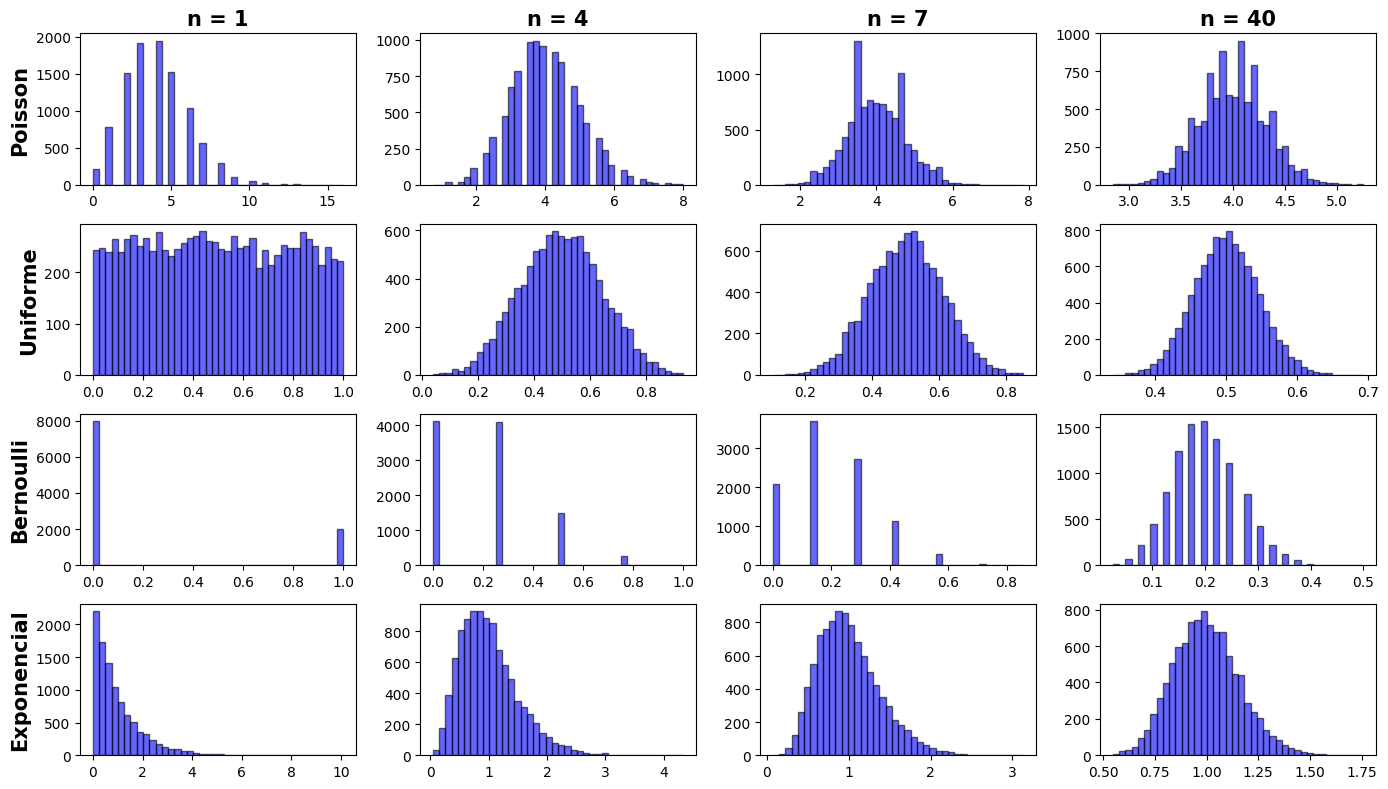

In [ ]:
import numpy as np 
import matplotlib.pyplot as plt

n_samples = 10000
samples = [1, 4, 7, 40]

#Generamos distribuciones
distribuciones = [
    ("Poisson", lambda size: np.random.poisson(4, size), 4 ,4 ),
    ("Uniforme", lambda size: np.random.uniform(0, 1, size), 0.5, 1/10),
    ("Bernoulli", lambda size: np.random.binomial(1, 0.2, size), 0.2, 0.2*0.7),
    ("Exponencial", lambda size: np.random.exponential(1.0, size), 1.0, 1.0),
]

# Creamos los espacios para las gráficas
fig, axes = plt.subplots(len(distribuciones), len(samples), figsize=(14, 8), sharey=False)


# Hacemos ciclo for para las pruebas y la grafícacion
for i , (name, func_gen, mu, var) in enumerate(distribuciones):
    for j, n in enumerate(samples):
        # Matriz
        M = func_gen((n_samples,n))
        # Promedio para cada n
        Zn = np.mean(M, axis = 1)
        
        # Graficación 
        ax = axes[i, j]
        ax.hist(Zn, bins=40, density=False, color='blue', edgecolor='black', alpha=0.6)
        if i == 0:
            ax.set_title(f"n = {n}", fontsize=15, fontweight='bold')
        if j == 0:
            ax.set_ylabel(name, fontsize=15, fontweight='bold')

plt.tight_layout()
plt.show()

        


### Demostración de porque la señal se pierde cuando hay muchas etapas


Figura guardada: markov.png


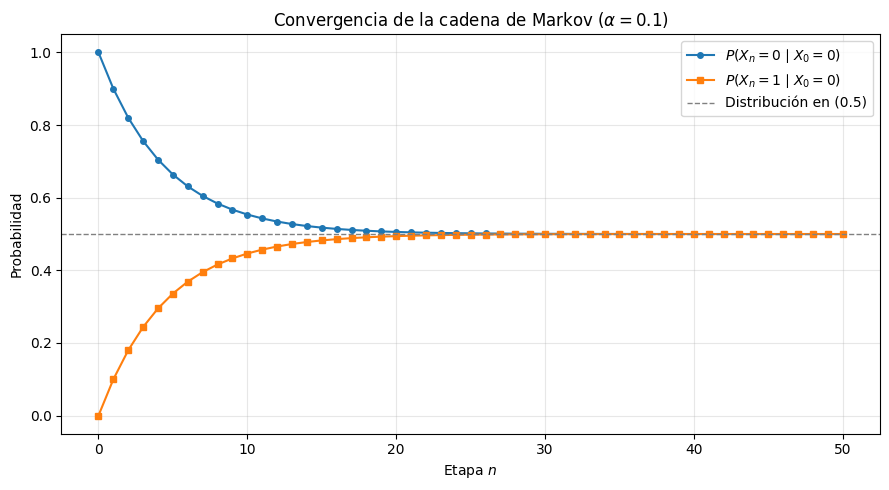

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# FUnción para generar la matriz y su multiplicación
def matriz(alfa, n_max=50):
    P = np.array([[1 - alfa, alfa],
                  [alfa, 1 - alfa]])
    w = np.array([1, 0])

    etapas = np.arange(0, n_max + 1)
    p0, p1 = [], []
    for i in etapas:
        Pn = np.linalg.matrix_power(P, i)

        # Multiplicamos por el estado inicial
        probn = w @ Pn
        p0.append(probn[0])
        p1.append(probn[1])
    return etapas, np.array(p0), np.array(p1)


alfa = 0.1
etapas, p0, p1 = matriz(alfa)

# Gráficamos
plt.figure(figsize=(9, 5))
plt.plot(etapas, p0, 'o-', label=r'$P(X_n = 0 \mid X_0 = 0)$', ms=4)
plt.plot(etapas, p1, 's-', label=r'$P(X_n = 1 \mid X_0 = 0)$', ms=4)
plt.axhline(0.5, ls='--', color='gray', lw=1, label='Distribución en (0.5)')

plt.xlabel('Etapa $n$')
plt.ylabel('Probabilidad')
plt.title(fr'Convergencia de la cadena de Markov ($\alpha = {alfa}$)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()